# Persistent top-1% recipients

Who qualifies persistently, and how old were they at first observed qualification?

**Scope:** Annual top-1% recipients in the shared 2020-2025 cohort, first grouped by streak length and then restricted to six-year persistent members. Profile tables count each recipient code once; growth retains the recipient-year detail.

The analysis begins with top-1% membership streaks and then focuses on recipients qualifying in all six years from 2020 through 2025. For these persistent recipients, the age question is age at their first observed top-1% appearance within this window, not their first-ever appearance before the data begins.

The [Methodology](../METHODOLOGY.md) documents definitions and correction policies. The [Project overview](../README.md) describes the notebook sequence and dataset rebuild process.

## Data inputs and chart configuration

The notebook loads the cleaned funding table and shared helpers. Codes remain text identifiers in loading, grouping and joins.

In [ ]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Locate the checkout from the project folder or a notebook subfolder.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "analysis_helpers.py").is_file()
     and (p / "config" / "sources.yaml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project folder.")
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from chart_style import apply_chart_style, colors_from_style, growth_cmap_from_style, load_chart_style

chart_style = load_chart_style(PROJECT_ROOT)
apply_chart_style(chart_style)
CHART_COLORS = colors_from_style(chart_style)
GROWTH_CMAP = growth_cmap_from_style(chart_style)
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
from analysis_helpers import (
    latest_recipient_names,
    build_top_1_presence,
    build_top_1_streaks,
    load_vmi_support_by_recipient,
    prepare_top_1_dataset,
)

vmi = load_vmi_support_by_recipient(PROJECT_ROOT)

vmi.head()




,tax_year,recipient_municipality,recipient_code,recipient_name,legal_form,requests,calculated_pmd_eur,legal_form_clean
0,2025,Kauno m. sav.,191678556,Socialinių inovacijų fondas,Labdaros ir paramos fondas,7,604.80,Labdaros ir paramos fondas
1,2025,Plungės r. sav.,170075590,"Sporto klubas ""Makabi""",Asociacija,4,192.18,Asociacija
2,2025,Kauno m. sav.,193158860,Moters užimtumo informacijos centras,Asociacija,4,316.10,Asociacija
3,2025,Vilniaus m. sav.,124467262,"Paramos fondas ""Švietimo ir tyrimų institutas""",Labdaros ir paramos fondas,19,985.02,Labdaros ir paramos fondas
4,2025,Jurbarko r. sav.,191250833,Skirsnemunės Šv. Jurgio parapija,Tradicinė religinė bendruomenė ar bendrija,9,788.37,Tradicinė religinė bendruomenė ar bendrija


## The shared annual top-1% definition

The cohort report shows retained and excluded records. Thresholds are calculated separately for each year from positive amounts, including ties at the threshold.

In [2]:
from cohort import START_YEAR, END_YEAR, LEGAL_FORM_REFERENCE_YEAR, filter_recipient_cohort, show_cohort_report
cohort_data, cohort_yearly_report, excluded_legal_forms, legal_form_changes = filter_recipient_cohort(vmi)
show_cohort_report(cohort_yearly_report, excluded_legal_forms, legal_form_changes)

df_filtered, top_1_df, yearly_thresholds = prepare_top_1_dataset(
    vmi,
    filter_year=LEGAL_FORM_REFERENCE_YEAR,
    percentile=99,
)

print("Rows in filtered data:", f"{len(df_filtered):,}")
print(
    "Unique recipients in filtered data:",
    f"{df_filtered['recipient_code'].nunique():,}",
)
print("Top 1% recipient-year records:", f"{len(top_1_df):,}")
print(
    "Unique recipients appearing in the annual top 1%:",
    f"{top_1_df['recipient_code'].nunique():,}",
)

print("\nTop 1% amount threshold for each year:")
display(
    yearly_thresholds.to_frame().style.format(
        {"top_1_threshold": "{:,.2f} €"}
    )
)


Legal forms observed in 2025; analysis years 2020-2025.
Filtering applies to recipient-year legal forms, not survival of each recipient in 2025.
Yearly inclusion and exclusion totals (amounts sum known values):


,tax_year,all_recipients,all_rows,all_pmd_eur,included_recipients,included_rows,included_pmd_eur,excluded_recipients,excluded_rows,excluded_pmd_eur,excluded_pmd_share,missing_amount_rows
0,2020,23240,23240,"21,654,753.19",16748,16748,"17,253,053.18",6492,6492,"4,401,700.01",20.33%,0
1,2021,22798,22798,"27,843,175.86",16325,16325,"22,940,811.40",6473,6473,"4,902,364.46",17.61%,0
2,2022,22147,22147,"29,202,852.20",15744,15744,"24,254,670.09",6403,6403,"4,948,182.11",16.94%,0
3,2023,22555,22555,"33,985,135.12",16252,16252,"28,543,797.48",6303,6303,"5,441,337.64",16.01%,0
4,2024,14511,14511,"36,904,168.23",14503,14503,"36,895,489.41",8,8,"8,678.82",0.02%,0
5,2025,15483,15483,"40,124,624.74",15483,15483,"40,124,624.74",0,0,0.00,0.00%,0


Excluded legal forms; absence is not evidence of legal ineligibility:


,legal_form_clean,exclusion_reason,recipients,rows,pmd_eur
0,Bendrija,Not observed in reference year,4048,13548,"4,267,247.25"
1,Biudžetinė įstaiga,Not observed in reference year,2436,8977,"13,942,264.28"
2,Mažoji bendrija,Not observed in reference year,15,54,"16,006.40"
3,"Prekybos, pramonės ir amatų rūmai",Not observed in reference year,4,13,"6,139.28"
4,Regiono plėtros taryba,Not observed in reference year,1,3,353.56
5,Sodininkų bendrija,Not observed in reference year,803,2869,"1,330,995.52"
6,Uždaroji akcinė bendrovė,Not observed in reference year,26,87,"83,911.66"
7,Šeimyna,Not observed in reference year,45,128,"55,345.09"


Recipients with multiple recorded legal forms: 0
The full legal_form_changes table retains every affected recipient-year; preview:


,recipient_code,recipient_name,tax_year,legal_form_clean,included_in_cohort


A recipient can appear in both inclusion groups within a year if its source records have different forms.


Rows in filtered data: 95,055
Unique recipients in filtered data: 23,401
Top 1% recipient-year records: 949
Unique recipients appearing in the annual top 1%: 302

Top 1% amount threshold for each year:


,top_1_threshold
tax_year,
2020,"9,710.19 €"
2021,"11,869.55 €"
2022,"12,492.24 €"
2023,"15,044.70 €"
2024,"19,907.18 €"
2025,"22,111.75 €"


## Consecutive top-1% membership

The calculation records each recipient's observed top-1% years and longest consecutive streak. A gap breaks a streak; having several qualifying years is not necessarily continuous membership.

In [3]:
top_1_presence = build_top_1_presence(top_1_df)
top_1_streaks = build_top_1_streaks(top_1_presence)

top_1_streaks.head()


,recipient_code,recipient_name,years_in_top_1,longest_consecutive_years,first_year_in_top_1,last_year_in_top_1,years_list
0,111959420,Nacionalinis vėžio institutas,4,4,2020,2023,"2020, 2021, 2022, 2023"
1,124009158,"Viešoji įstaiga ""Vilniaus SOS vaikų kaimas""",1,1,2025,2025,2025
2,124364561,Viešoji įstaiga Vilniaus universiteto ligoninė...,1,1,2023,2023,2023
3,124865775,"Viešoji įstaiga ""ProMusic Agency""",1,1,2022,2022,2022
4,125534792,Abraomo Kulviečio klasikinės gimnazijos labdar...,1,1,2020,2020,2020


## Funding by membership streak length

Each streak group has two funding measures: funding during qualifying years and funding in all recorded cohort years for the same recipients. The qualifying-year total is included in the all-year total, so the two measures are not additive. The combined chart and two separate charts below show the same measures; the separate charts share a scale for comparison.

In [4]:
# Funding received only in years when each recipient was in the top 1%.
top1_totals = top_1_df.groupby("recipient_code").agg(
    pmd_top1_years=("calculated_pmd_eur", "sum")
)

# All recorded funding for the same recipients in the filtered period.
all_year_totals = (
    df_filtered.loc[
        df_filtered["recipient_code"].isin(top_1_streaks["recipient_code"])
    ]
    .groupby("recipient_code")
    .agg(pmd_all_years=("calculated_pmd_eur", "sum"))
)

persistence_recipient_totals = (
    top_1_streaks
    .merge(top1_totals, on="recipient_code", validate="one_to_one")
    .merge(all_year_totals, on="recipient_code", validate="one_to_one")
)

persistence_summary = (
    persistence_recipient_totals
    .groupby("longest_consecutive_years", as_index=False)
    .agg(
        unique_recipients=("recipient_code", "nunique"),
        pmd_top1_years=("pmd_top1_years", "sum"),
        pmd_all_years=("pmd_all_years", "sum"),
    )
)

persistence_summary["pmd_outside_top1_years"] = (
    persistence_summary["pmd_all_years"]
    - persistence_summary["pmd_top1_years"]
)

assert persistence_summary["pmd_outside_top1_years"].ge(-0.01).all()

display(persistence_summary.style.format({
    "unique_recipients": "{:,.0f}",
    "pmd_top1_years": "{:,.2f} €",
    "pmd_all_years": "{:,.2f} €",
    "pmd_outside_top1_years": "{:,.2f} €",
}))

,longest_consecutive_years,unique_recipients,pmd_top1_years,pmd_all_years,pmd_outside_top1_years
0,1,123,"3,115,851.66 €","5,946,193.03 €","2,830,341.37 €"
1,2,32,"2,062,934.88 €","2,706,761.46 €","643,826.58 €"
2,3,22,"1,972,873.90 €","2,373,320.81 €","400,446.91 €"
3,4,31,"3,398,953.56 €","3,735,100.64 €","336,147.08 €"
4,5,17,"3,632,856.87 €","3,767,422.54 €","134,565.67 €"
5,6,77,"70,821,962.20 €","70,821,962.20 €",0.00 €


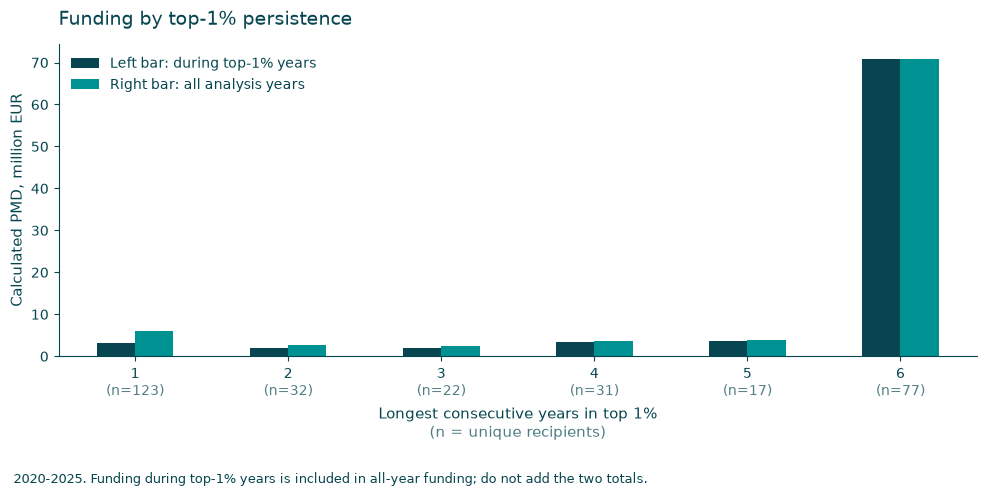

,unique_recipients,pmd_top1_years,pmd_all_years,pmd_outside_top1_years
longest_consecutive_years,,,,
1,123,3115851.66,5946193.03,2830341.37
2,32,2062934.88,2706761.46,643826.58
3,22,1972873.90,2373320.81,400446.91
4,31,3398953.56,3735100.64,336147.08
5,17,3632856.87,3767422.54,134565.67
6,77,70821962.20,70821962.20,0.00


In [5]:
from chart_style import finish_chart, growth_boxplot, contrast_text

# Compare funding during qualifying years with full-period funding.
plot_summary = (
    persistence_summary
    .sort_values("longest_consecutive_years")
    .set_index("longest_consecutive_years")
)

ax = plot_summary[
    ["pmd_top1_years", "pmd_all_years"]
].plot.bar(
    figsize=(10, 5),
    color=[
        CHART_COLORS["primary"],
        CHART_COLORS["secondary"],
    ],
)

ax.set_xticklabels(
    [
        f"{years}\n(n={count})"
        for years, count in zip(
            plot_summary.index,
            plot_summary["unique_recipients"],
        )
    ],
    rotation=0,
)

ax.set_title("Funding by top-1% persistence")
ax.set_xlabel(
    "Longest consecutive years in top 1%\n"
    "(n = unique recipients)"
)
ax.set_ylabel("Calculated PMD, million EUR")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.1f}")
)

ax.legend([
    "Left bar: during top-1% years",
    "Right bar: all analysis years",
])

finish_chart(plt.gcf(), '2020-2025. Funding during top-1% years is included in all-year funding; do not add the two totals.')

display(plot_summary)


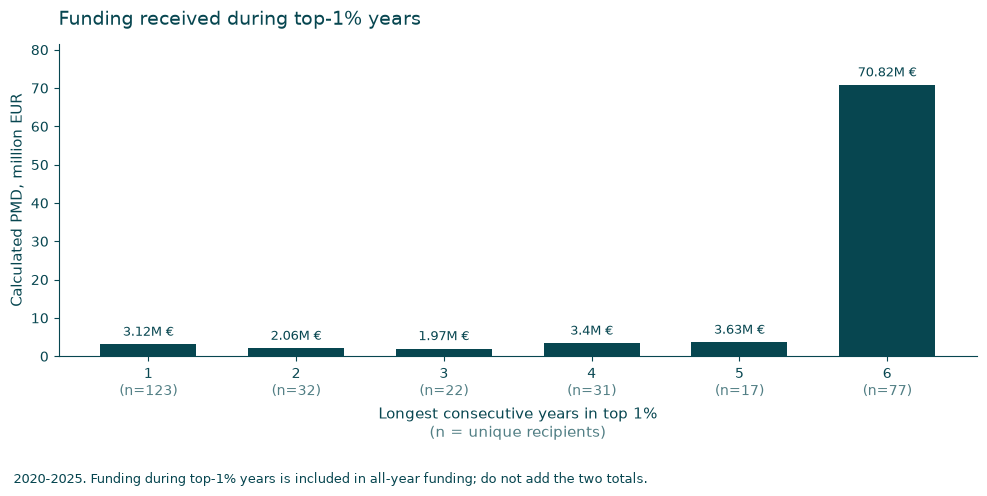

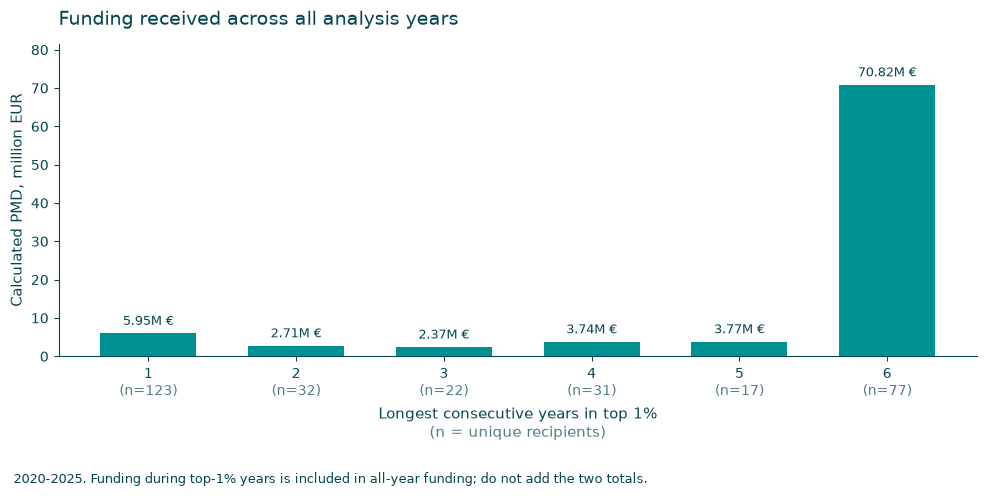

,unique_recipients,pmd_top1_years,pmd_all_years,pmd_outside_top1_years
longest_consecutive_years,,,,
1,123,3115851.66,5946193.03,2830341.37
2,32,2062934.88,2706761.46,643826.58
3,22,1972873.90,2373320.81,400446.91
4,31,3398953.56,3735100.64,336147.08
5,17,3632856.87,3767422.54,134565.67
6,77,70821962.20,70821962.20,0.00


In [6]:
from chart_style import finish_chart, growth_boxplot, contrast_text

# Use the same recipient groups and scale in both charts.
plot_summary = (
    persistence_summary
    .sort_values("longest_consecutive_years")
    .set_index("longest_consecutive_years")
)

x_labels = [
    f"{years}\n(n={count:,})"
    for years, count in zip(
        plot_summary.index,
        plot_summary["unique_recipients"],
    )
]

shared_max = plot_summary[
    ["pmd_top1_years", "pmd_all_years"]
].max().max()

charts = [
    (
        "pmd_top1_years",
        "Funding received during top-1% years",
        CHART_COLORS["primary"],
    ),
    (
        "pmd_all_years",
        "Funding received across all analysis years",
        CHART_COLORS["secondary"],
    ),
]

for column, title, color in charts:
    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.bar(
        x_labels,
        plot_summary[column],
        color=color,
        width=0.65,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value / 1_000_000:.2f}M €"
            for value in plot_summary[column]
        ],
        padding=4,
        fontsize=9,
    )

    ax.set_title(title)
    ax.set_xlabel(
        "Longest consecutive years in top 1%\n"
        "(n = unique recipients)"
    )
    ax.set_ylabel("Calculated PMD, million EUR")
    ax.set_ylim(0, max(shared_max, 1) * 1.15)

    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x / 1_000_000:.1f}")
    )

    finish_chart(plt.gcf(), '2020-2025. Funding during top-1% years is included in all-year funding; do not add the two totals.')
display(plot_summary)


## The six-year persistent recipient group

This table retains recipients qualifying in all six years. The overall average per request is total funding divided by total requests. The median annual amount per request is a median of annual ratios, not the median of individual requests. Municipalities and legal forms in this overview use the first recorded qualifying-year value.

In [7]:
persistent_recipients = top_1_streaks[top_1_streaks["longest_consecutive_years"] == 6].copy()
persistent_codes = persistent_recipients["recipient_code"].unique()

top_1_persistent_df = top_1_df[top_1_df["recipient_code"].isin(persistent_codes)].copy()
top_1_persistent_df["pmd_per_request"] = (
    top_1_persistent_df["calculated_pmd_eur"]
    / top_1_persistent_df["requests"].where(
        top_1_persistent_df["requests"] > 0
    )
)

persistent_recipient_overview = (
    top_1_persistent_df.groupby("recipient_code")
      .agg(
          municipality=("recipient_municipality", "first"),
          legal_form=("legal_form_clean", "first"),
          years_present=("tax_year", lambda x: ", ".join(map(str, sorted(x.unique())))),
          total_pmd_eur=("calculated_pmd_eur", "sum"),
          total_requests=("requests", "sum"),
          median_pmd_eur=("calculated_pmd_eur", "median"),
          max_pmd_eur=("calculated_pmd_eur", "max"),
          median_annual_amount_per_request=("pmd_per_request", "median")
      )
      .reset_index()
      .sort_values("total_pmd_eur", ascending=False)
)

persistent_recipient_overview.insert(1, "recipient_name",
    persistent_recipient_overview["recipient_code"].map(latest_recipient_names(df_filtered)))
# Weight each annual average by its number of requests.
persistent_recipient_overview["average_amount_per_request"] = (
    persistent_recipient_overview["total_pmd_eur"]
    / persistent_recipient_overview["total_requests"].where(
        persistent_recipient_overview["total_requests"] > 0
    )
)
persistent_recipient_overview.head(20)


,recipient_code,recipient_name,municipality,legal_form,years_present,total_pmd_eur,total_requests,median_pmd_eur,max_pmd_eur,median_annual_amount_per_request,average_amount_per_request
60,303420560,"VšĮ ""Mėlyna ir geltona""",Vilniaus m. sav.,Viešoji įstaiga,"2020, 2021, 2022, 2023, 2024, 2025",12227860.88,161322,2258361.240,3068047.50,72.977772,75.797851
48,302721009,Rimanto Kaukėno paramos grupė,Vilniaus m. sav.,Labdaros ir paramos fondas,"2020, 2021, 2022, 2023, 2024, 2025",4988828.38,85233,693044.020,1471194.93,57.732979,58.531653
36,301753623,Tėvynės sąjunga-Lietuvos krikščionys demokratai,Vilniaus m. sav.,Politinė partija,"2020, 2021, 2022, 2023, 2024, 2025",4597681.10,86820,698324.490,1176651.17,52.570254,52.956474
37,302288579,"Paramos ir labdaros fondas ""Mamų unija""",Vilniaus r. sav.,Labdaros ir paramos fondas,"2020, 2021, 2022, 2023, 2024, 2025",4200156.71,79222,668168.290,1003965.20,53.254022,53.017555
71,305017992,"VšĮ ""Savanoriai vaikams""",Vilniaus m. sav.,Viešoji įstaiga,"2020, 2021, 2022, 2023, 2024, 2025",2951463.31,51544,353281.525,1016991.27,54.286972,57.261045
65,304405807,Laisvės TV,Vilniaus m. sav.,Viešoji įstaiga,"2020, 2021, 2022, 2023, 2024, 2025",2502821.57,40194,415528.730,497917.54,63.021406,62.268537
7,190740859,Maltos ordino pagalbos tarnyba,Vilniaus m. sav.,Asociacija,"2020, 2021, 2022, 2023, 2024, 2025",2488247.28,42404,374462.850,613820.81,58.489663,58.679542
34,301536790,"VšĮ ""PENKTA KOJA""",Kauno m. sav.,Viešoji įstaiga,"2020, 2021, 2022, 2023, 2024, 2025",2340164.44,48424,367797.085,545210.16,46.643619,48.326541
73,305205154,Laisvės partija,Vilniaus m. sav.,Politinė partija,"2020, 2021, 2022, 2023, 2024, 2025",1491247.94,32964,258389.635,297681.43,45.707104,45.238683
57,303379747,"Paramos fondas ""Gerų darbų dirbtuvės""",Vilniaus m. sav.,Labdaros ir paramos fondas,"2020, 2021, 2022, 2023, 2024, 2025",1450201.35,28547,198134.395,424862.40,48.354535,50.800482


## Recipient-year age linkage

Organization age is linked by recipient code and tax year, with codes stored as text in both tables. Unknown age remains a separate category. Age is tax year minus registration year, not an exact birthday-based age.

In [8]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

recipient_age = pd.read_csv(
    PROCESSED_DIR / "recipient_analysis.csv",
    usecols=[
        "tax_year",
        "recipient_code",
        "organization_age",
        "organization_age_group",
    ],
    dtype={"recipient_code": "string"},
    low_memory=False,
)

recipient_age["tax_year"] = pd.to_numeric(
    recipient_age["tax_year"], errors="coerce"
)
recipient_age["recipient_code"] = recipient_age["recipient_code"].str.strip()
recipient_age["organization_age"] = pd.to_numeric(
    recipient_age["organization_age"], errors="coerce"
)

# Rebuild the persistent subset so this cell does not reuse an older version.
persistent_recipients = top_1_streaks.loc[
    top_1_streaks["longest_consecutive_years"] == 6
].copy()

persistent_codes = (
    persistent_recipients["recipient_code"].astype("string").str.strip()
)

top_1_persistent_df = top_1_df.copy()
top_1_persistent_df["recipient_code"] = (
    top_1_persistent_df["recipient_code"].astype("string").str.strip()
)
top_1_persistent_df = top_1_persistent_df.loc[
    top_1_persistent_df["recipient_code"].isin(persistent_codes)
].copy()

top_1_persistent_df["tax_year"] = pd.to_numeric(
    top_1_persistent_df["tax_year"], errors="coerce"
)
top_1_persistent_df["pmd_per_request"] = (
    top_1_persistent_df["calculated_pmd_eur"]
    / top_1_persistent_df["requests"].where(
        top_1_persistent_df["requests"] > 0
    )
)

top_1_persistent_with_age = top_1_persistent_df.merge(
    recipient_age,
    on=["tax_year", "recipient_code"],
    how="left",
    validate="one_to_one",
)

top_1_persistent_with_age["organization_age_group"] = (
    top_1_persistent_with_age["organization_age_group"]
    .astype("string")
    .fillna("Unknown")
    .replace({
        "10-Jun": "6-10",
        "15-Nov": "11-15",
        "nan": "Unknown",
        "NaN": "Unknown",
        "<NA>": "Unknown",
    })
)

age_order = [
    "0-5", "6-10", "11-15", "16-20", "21-25",
    "26-30", "31-35", "36-40", "41+", "Unknown",
]

top_1_persistent_with_age["organization_age_group"] = pd.Categorical(
    top_1_persistent_with_age["organization_age_group"],
    categories=age_order,
    ordered=True,
)

top_1_persistent_with_age.head()

,tax_year,recipient_municipality,recipient_code,recipient_name,legal_form,requests,calculated_pmd_eur,legal_form_clean,top_1_threshold,pmd_per_request,organization_age,organization_age_group
0,2025,Ukmergės r. sav.,304173981,"VšĮ ""Klajūnas""",Viešoji įstaiga,1410,69882.80,Viešoji įstaiga,22111.7545,49.562270,9.0,6-10
1,2025,Kauno m. sav.,191691799,Lietuvos šaulių sąjunga,Asociacija,2226,175236.01,Asociacija,22111.7545,78.722376,25.0,21-25
2,2025,Vilniaus m. sav.,192015172,"Labdaros ir paramos fondas ""Maisto bankas""",Labdaros ir paramos fondas,1216,69701.73,Labdaros ir paramos fondas,22111.7545,57.320502,29.0,26-30
3,2025,Vilniaus m. sav.,195736590,Socialinio draudimo darbuotojų profesinė sąjunga,Profesinė sąjunga ar susivienijimas,1029,39174.15,Profesinė sąjunga ar susivienijimas,22111.7545,38.070117,24.0,21-25
4,2025,Vilniaus m. sav.,192014985,SOS VAIKŲ KAIMŲ LIETUVOJE DRAUGIJA,Labdaros ir paramos fondas,1593,114186.81,Labdaros ir paramos fondas,22111.7545,71.680358,29.0,26-30


## How old were recipients at first observed qualification?

The age comparison contains one row per persistent recipient, taken from their earliest observed top-1% year: 2020 for this six-year group. The bar chart counts unique recipients in that year's age group. It cannot establish when they first qualified before 2020.

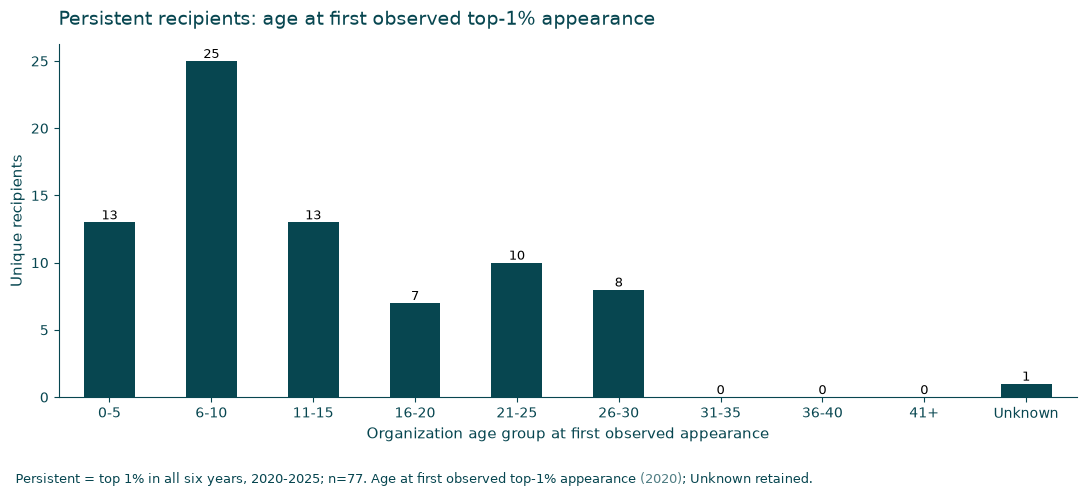

,Unique recipients
organization_age_group,
0-5,13
6-10,25
11-15,13
16-20,7
21-25,10
26-30,8
31-35,0
36-40,0
41+,0


In [9]:
from chart_style import finish_chart, growth_boxplot, contrast_text

# One record per persistent recipient: their first observed top-1% year.
persistent_first_top1 = (
    top_1_persistent_with_age
    .sort_values(["recipient_code", "tax_year"])
    .drop_duplicates("recipient_code", keep="first")
    .copy()
)

first_top1_age_counts = (
    persistent_first_top1
    .groupby("organization_age_group", observed=False)["recipient_code"]
    .nunique()
    .reindex(age_order, fill_value=0)
)

assert first_top1_age_counts.sum() == persistent_first_top1["recipient_code"].nunique()

ax = first_top1_age_counts.plot(
    kind="bar",
    figsize=(11, 5),
    color=CHART_COLORS["primary"],
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=9, color="black")

ax.set_title("Persistent recipients: age at first observed top-1% appearance")
ax.set_xlabel("Organization age group at first observed appearance")
ax.set_ylabel("Unique recipients")
plt.xticks(rotation=0)

finish_chart(plt.gcf(), f"Persistent = top 1% in all six years, 2020-2025; n={first_top1_age_counts.sum():,}. Age at first observed top-1% appearance (2020); Unknown retained.")


display(first_top1_age_counts.rename("Unique recipients").to_frame())


## Recipients represented in the 0-5 age group

This table uses exactly the same first-qualification records as the chart. The assertion checks that its row count matches the 0-5 age-group bar; it is not a list of everyone ever aged 0-5 during the period.

In [10]:
persistent_age_0_5_unique = (
    persistent_first_top1.loc[
        persistent_first_top1["organization_age_group"] == "0-5",
        [
            "recipient_code", "recipient_name", "recipient_municipality",
            "tax_year", "organization_age", "organization_age_group",
            "requests", "calculated_pmd_eur",
        ],
    ]
    .sort_values(["organization_age", "recipient_name"])
    .rename(columns={
        "tax_year": "first_observed_top1_year",
        "organization_age": "age_at_first_observed_top1",
    })
    .copy()
)

assert len(persistent_age_0_5_unique) == int(first_top1_age_counts.loc["0-5"])

print(f"Recipients aged 0–5 at first observed top-1% appearance: {len(persistent_age_0_5_unique)}")
display(persistent_age_0_5_unique)

Recipients aged 0–5 at first observed top-1% appearance: 13


,recipient_code,recipient_name,recipient_municipality,first_observed_top1_year,age_at_first_observed_top1,organization_age_group,requests,calculated_pmd_eur
393,305529398,Nacionalinis susivienijimas,Vilniaus m. sav.,2020,0.0,0-5,1583,41270.88
418,305433631,"Viešoji įstaiga ""Sengirės fondas""",Vilniaus r. sav.,2020,0.0,0-5,723,33790.99
443,305205154,Laisvės partija,Vilniaus m. sav.,2020,1.0,0-5,4036,148041.71
416,305187044,Lietuvos švietimo ir mokslo profesinė sąjunga,Vilniaus m. sav.,2020,1.0,0-5,1162,25780.56
392,305017992,"VšĮ ""Savanoriai vaikams""",Vilniaus m. sav.,2020,1.0,0-5,3313,171503.52
433,304751823,Beglobių gyvūnų labdaros ir paramos fondas,Kauno r. sav.,2020,2.0,0-5,388,13313.80
452,304960260,Keturkojo viltis,Alytaus m. sav.,2020,2.0,0-5,1021,30261.72
425,304856030,Santaros klinikų gydytojų sąjunga,Vilniaus m. sav.,2020,2.0,0-5,301,18229.31
414,304727929,Lietuvos šeimos gydytojų profesinė sąjunga,Kauno m. sav.,2020,3.0,0-5,286,11791.38
460,304447261,"VšĮ ""Šuniukų fėja""",Klaipėdos m. sav.,2020,3.0,0-5,879,23508.70


## Where are persistent recipients registered?

Each recipient's full-period funding is assigned to their latest recorded municipality. The chart shows up to 20 municipalities and counts each recipient once. This describes registered recipient locations, not where supporters live or where funding is spent.

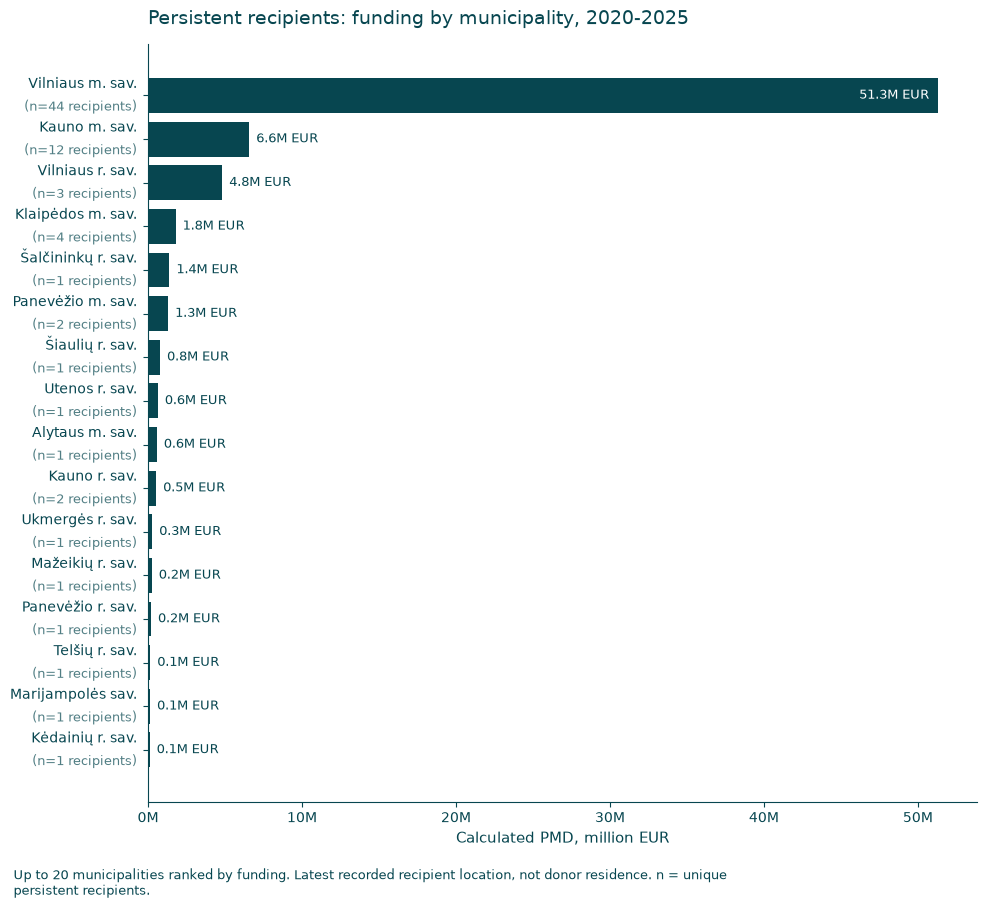

,recipient_municipality,unique_recipients,total_pmd_eur
4,Kėdainių r. sav.,1,111337.64
5,Marijampolės sav.,1,135056.62
9,Telšių r. sav.,1,148555.65
8,Panevėžio r. sav.,1,195312.55
6,Mažeikių r. sav.,1,247055.54
10,Ukmergės r. sav.,1,273187.87
2,Kauno r. sav.,2,531826.35
0,Alytaus m. sav.,1,575962.30
11,Utenos r. sav.,1,641916.82
15,Šiaulių r. sav.,1,784026.10


In [11]:
from chart_style import finish_chart, growth_boxplot, contrast_text

persistent_recipient_totals = (
    top_1_persistent_with_age
    .sort_values(["recipient_code", "tax_year"])
    .groupby("recipient_code", as_index=False)
    .agg(
        recipient_municipality=("recipient_municipality", "last"),
        total_pmd_eur=("calculated_pmd_eur", "sum")
    )
)

persistent_municipality_summary = (
    persistent_recipient_totals
    .groupby("recipient_municipality", as_index=False)
    .agg(
        unique_recipients=("recipient_code", "nunique"),
        total_pmd_eur=("total_pmd_eur", "sum")
    )
    .sort_values("total_pmd_eur", ascending=False)
)

persistent_municipality_summary = persistent_municipality_summary.head(20)
plot_df = persistent_municipality_summary.sort_values("total_pmd_eur", ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, max(5, .45 * len(plot_df) + 2)))
bars = ax.barh(range(len(plot_df)), plot_df["total_pmd_eur"], color=CHART_COLORS["primary"])
ax.set_yticks(range(len(plot_df)), [""] * len(plot_df))
for y, (_, row) in enumerate(plot_df.iterrows()):
    ax.annotate(row["recipient_municipality"], (0, y), xycoords=ax.get_yaxis_transform(), xytext=(-8, 3), textcoords="offset points", ha="right", va="bottom", fontsize=10)
    ax.annotate(f"(n={row['unique_recipients']:,} recipients)", (0, y), xycoords=ax.get_yaxis_transform(), xytext=(-8, -3), textcoords="offset points", ha="right", va="top", fontsize=9)
largest = int(np.argmax(plot_df["total_pmd_eur"].to_numpy()))
for i, (bar, value) in enumerate(zip(bars, plot_df["total_pmd_eur"])):
    inside = i == largest
    ax.annotate(f"{value / 1_000_000:.1f}M EUR", (value, bar.get_y() + bar.get_height()/2), xytext=(-6 if inside else 5, 0), textcoords="offset points", ha="right" if inside else "left", va="center", fontsize=9, color=contrast_text(bar.get_facecolor()) if inside else CHART_COLORS["foreground"])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1_000_000:.1f}M"))
ax.set(title="Persistent recipients: funding by municipality, 2020-2025", xlabel="Calculated PMD, million EUR", ylabel="")
finish_chart(plt.gcf(), 'Up to 20 municipalities ranked by funding. Latest recorded recipient location, not donor residence. n = unique persistent recipients.')

display(plot_df)


## Overall funding per request

Persistent recipients are ranked by total funding divided by total requests across the period. Zero total requests give an unavailable ratio. This is an average allocation per recorded request, not a direct estimate of supporters' wealth.

In [12]:
persistent_amount_per_request = (
    top_1_persistent_with_age
    .groupby("recipient_code", as_index=False)
    .agg(
        municipality=("recipient_municipality", "last"),
        years_present=("tax_year", lambda x: ", ".join(map(str, sorted(x.unique())))),
        total_requests=("requests", "sum"),
        total_pmd_eur=("calculated_pmd_eur", "sum")
    )
)

persistent_amount_per_request.insert(1, "recipient_name",
    persistent_amount_per_request["recipient_code"].map(latest_recipient_names(df_filtered)))

persistent_amount_per_request["average_amount_per_request"] = np.where(
    persistent_amount_per_request["total_requests"] > 0,
    persistent_amount_per_request["total_pmd_eur"] / persistent_amount_per_request["total_requests"],
    np.nan
)

persistent_amount_per_request = persistent_amount_per_request.sort_values(
    "average_amount_per_request",
    ascending=False
)

persistent_amount_per_request["total_pmd_eur"] = persistent_amount_per_request["total_pmd_eur"].round(2)
persistent_amount_per_request["average_amount_per_request"] = (
    persistent_amount_per_request["average_amount_per_request"].round(2)
)

persistent_amount_per_request.head(30)


,recipient_code,recipient_name,municipality,years_present,total_requests,total_pmd_eur,average_amount_per_request
27,300556352,Vilniaus licėjaus labdaros ir paramos fondas,Vilniaus m. sav.,"2020, 2021, 2022, 2023, 2024, 2025",1162,168044.78,144.62
23,291812440,Vilniaus jėzuitų gimnazija,Vilniaus m. sav.,"2020, 2021, 2022, 2023, 2024, 2025",2736,341999.00,125.00
25,300109458,Kauno jėzuitų gimnazija,Kauno m. sav.,"2020, 2021, 2022, 2023, 2024, 2025",3482,431276.38,123.86
43,302627435,Šv. Juozapo mokykla,Vilniaus m. sav.,"2020, 2021, 2022, 2023, 2024, 2025",1519,161147.02,106.09
62,303503497,"VšĮ ""Kauno hospiso namai""",Kauno r. sav.,"2020, 2021, 2022, 2023, 2024, 2025",2735,271966.15,99.44
69,304856030,Santaros klinikų gydytojų sąjunga,Vilniaus m. sav.,"2020, 2021, 2022, 2023, 2024, 2025",2564,205854.65,80.29
15,191691799,Lietuvos šaulių sąjunga,Kauno m. sav.,"2020, 2021, 2022, 2023, 2024, 2025",8664,659402.89,76.11
60,303420560,"VšĮ ""Mėlyna ir geltona""",Vilniaus m. sav.,"2020, 2021, 2022, 2023, 2024, 2025",161322,12227860.88,75.80
50,302868589,Kauno Jono Pauliaus II gimnazija,Kauno m. sav.,"2020, 2021, 2022, 2023, 2024, 2025",1875,135043.56,72.02
18,192015172,"Labdaros ir paramos fondas ""Maisto bankas""",Vilniaus m. sav.,"2020, 2021, 2022, 2023, 2024, 2025",5814,395346.16,68.00


## Distribution of recipient-level averages

Each recipient with a defined overall average contributes once to these statistics. The count is a number of recipients; other values are euros per request. The mean here is an unweighted mean of recipient averages, not the pooled funding-to-requests ratio.

In [13]:
average_amount_stats = (
    persistent_amount_per_request["average_amount_per_request"]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .to_frame(name="average_amount_per_request")
)

average_amount_stats_formatted = average_amount_stats.copy()

column = "average_amount_per_request"

average_amount_stats_formatted[column] = [
    (
        "No data"
        if pd.isna(value)
        else f"{value:,.0f}"
        if statistic == "count"
        else f"{value:,.2f} €"
    )
    for statistic, value in average_amount_stats[column].items()
]

display(average_amount_stats_formatted)


,average_amount_per_request
count,77
mean,55.38 €
std,21.00 €
min,15.68 €
10%,38.32 €
25%,42.83 €
50%,51.50 €
75%,60.61 €
90%,73.53 €
95%,100.77 €


## Annual and fixed-period growth

Annual columns use consecutive years; the whole-period column uses 2020 and 2025. These are changes in funding, not changes in rank. The heatmap uses the shared theme: purple decline, pink neutral, green growth and light grey unavailable comparisons.

In [14]:
from growth_analysis import build_growth_analysis, growth_table as make_growth_table, render_growth_heatmap, render_short_histories
from cohort import START_YEAR, END_YEAR

recipient_year_amounts, period_summary = build_growth_analysis(top_1_persistent_with_age, start=START_YEAR, end=END_YEAR)
growth_table, recipient_labels = make_growth_table(recipient_year_amounts, period_summary, START_YEAR, END_YEAR)
growth_table.head()


tax_year,2021,2022,2023,2024,2025,Growth 2020-2025,Annualized 2020-2025
Recipient,,,,,,,
303420560,117.239398,-0.115495,0.256610,0.290401,-0.109228,150.061429,1.727914
191368760,1.330829,0.613750,1.306883,0.056062,0.102842,9.105896,0.588236
305706699,-0.253091,-0.634848,5.136421,3.044283,0.253217,7.482503,0.533574
302704554,0.581741,0.507080,0.518807,0.707749,0.365938,7.445579,0.532237
302869488,0.181149,0.045849,0.874140,1.779737,0.214800,6.817797,0.508749


## Growth comparison coverage

The coverage table reports the available fixed-period comparisons underlying the heatmap. Six-year qualification implies complete qualifying-year coverage under the current selection rule.

In [15]:
period_summary.groupby("fixed_period_status").agg(recipients=("recipient_code", "nunique"))


,recipients
fixed_period_status,
Available,77


In [16]:
render_growth_heatmap(growth_table, recipient_labels, GROWTH_CMAP, CHART_COLORS)


tax_year,2021,2022,2023,2024,2025,Growth 2020-2025,Annualized 2020-2025
Recipient,,,,,,,
"VšĮ ""Mėlyna ir geltona""","+11,723.9%",-11.5%,+25.7%,+29%,-10.9%,"+15,006.1%",+172.8%
LIETUVOS GYDYTOJŲ SĄJUNGA,+133.1%,+61.4%,+130.7%,+5.6%,+10.3%,+910.6%,+58.8%
"VšĮ ""Tiesa yra svarbu""",-25.3%,-63.5%,+513.6%,+304.4%,+25.3%,+748.3%,+53.4%
Pagalbos onkologiniams ligoniams asociacija,+58.2%,+50.7%,+51.9%,+70.8%,+36.6%,+744.6%,+53.2%
"Neišnešiotų naujagimių asociacija ""Neišnešiotukas""",+18.1%,+4.6%,+87.4%,+178%,+21.5%,+681.8%,+50.9%
Lietuvos šaulių sąjunga,+113.9%,-4.1%,+46.3%,+175.3%,-27.9%,+495.1%,+42.9%
"VšĮ ""Savanoriai vaikams""",+20.7%,+10.4%,+109.3%,+77.7%,+19.7%,+493%,+42.8%
"VšĮ ""Kauno hospiso namai""",+217.3%,-5.8%,+68.6%,+11.6%,+2.7%,+477.5%,+42%
Beglobių gyvūnų labdaros ir paramos fondas,+44.2%,+90.2%,+65.1%,-7.1%,+33%,+459.8%,+41.1%


## Appendix: shorter-history check

This shared diagnostic should be empty for a correctly selected six-year persistent group. A nonempty report would require checking the selection and input coverage; it is not an additional comparison group.

In [17]:
render_short_histories(period_summary, START_YEAR, END_YEAR)


Recipient,First year,Last year,Observed years,Elapsed years,Observed-period growth,Annualized observed growth,History status


## Reading the results together

Persistence, funding scale and age at first observed qualification describe different aspects of these recipients. None of them alone establishes why an organization repeatedly qualifies.

[Previous notebook](04_top_1_percent_overview.ipynb) | [Next notebook](06_top_1_newcomers_vs_returning.ipynb) | [Reading guide](../README.md#reading-order)